In [70]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings 


In [71]:
from pathlib import Path
cwd = Path.cwd()
data_path = next(
    (
        candidate
        for base in (cwd, *cwd.parents)
        for candidate in (base / "raw" / "used_cars.csv", base / "carvenv" / "raw" / "used_cars.csv")
        if candidate.is_file()
    ),
    None,
)
if data_path is None:
    raise FileNotFoundError(f"Could not find raw/used_cars.csv starting from {cwd}")
df = pd.read_csv(data_path)

In [72]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [73]:
df.columns.to_list()

['brand',
 'model',
 'model_year',
 'milage',
 'fuel_type',
 'engine',
 'transmission',
 'ext_col',
 'int_col',
 'accident',
 'clean_title',
 'price']

In [74]:
df.shape

(4009, 12)

In [75]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 376.0 KB


In [76]:
df.isnull().sum().sort_values(ascending=False)

clean_title     596
fuel_type       170
accident        113
brand             0
milage            0
model_year        0
model             0
engine            0
ext_col           0
transmission      0
int_col           0
price             0
dtype: int64

In [77]:
(df.isnull().mean() * 100).sort_values(ascending=False).round(2)

clean_title     14.87
fuel_type        4.24
accident         2.82
brand            0.00
milage           0.00
model_year       0.00
model            0.00
engine           0.00
ext_col          0.00
transmission     0.00
int_col          0.00
price            0.00
dtype: float64

In [78]:
df["price"].head(10)


0    $10,300
1    $38,005
2    $54,598
3    $15,500
4    $34,999
5    $14,798
6    $31,000
7     $7,300
8    $41,927
9    $69,950
Name: price, dtype: str

In [79]:
df["price"] = (
    df["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

In [80]:
df["price"].head(10)

0    10300.0
1    38005.0
2    54598.0
3    15500.0
4    34999.0
5    14798.0
6    31000.0
7     7300.0
8    41927.0
9    69950.0
Name: price, dtype: float64

In [81]:
df["milage"].head(10)

0     51,000 mi.
1     34,742 mi.
2     22,372 mi.
3     88,900 mi.
4      9,835 mi.
5    136,397 mi.
6     84,000 mi.
7    242,000 mi.
8     23,436 mi.
9     34,000 mi.
Name: milage, dtype: str

In [82]:
df["milage"] = (
    df["milage"]
    .str.replace(",", "", regex=False)
    .str.replace(" mi.", "", regex=False)
    .astype(float)
)

In [83]:
df["milage"].head(10)

0     51000.0
1     34742.0
2     22372.0
3     88900.0
4      9835.0
5    136397.0
6     84000.0
7    242000.0
8     23436.0
9     34000.0
Name: milage, dtype: float64

In [84]:
df.head(10)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500.0
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0
5,Acura,ILX 2.4L,2016,136397.0,Gasoline,2.4 Liter,F,Silver,Ebony.,None reported,NaN,14798.0
6,Audi,S3 2.0T Premium Plus,2017,84000.0,Gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,None reported,Yes,31000.0
7,BMW,740 iL,2001,242000.0,Gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,None reported,Yes,7300.0
8,Lexus,RC 350 F Sport,2021,23436.0,Gasoline,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Black,Black,None reported,Yes,41927.0
9,Tesla,Model X Long Range Plus,2020,34000.0,NaN,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,None reported,Yes,69950.0


In [85]:
df["engine"].nunique()

1146

In [86]:
df["engine"].value_counts().head(20)

engine
2.0L I4 16V GDI DOHC Turbo                               52
355.0HP 5.3L 8 Cylinder Engine Gasoline Fuel             48
420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel             47
–                                                        45
300.0HP 3.0L Straight 6 Cylinder Engine Gasoline Fuel    44
240.0HP 2.0L 4 Cylinder Engine Gasoline Fuel             42
285.0HP 3.6L V6 Cylinder Engine Gasoline Fuel            40
5.7L V8 16V MPFI OHV                                     29
340.0HP 3.0L V6 Cylinder Engine Gasoline Fuel            28
3.6L V6 24V MPFI DOHC                                    28
3.6L V6 24V GDI DOHC                                     28
268.0HP 3.5L V6 Cylinder Engine Gasoline Fuel            24
455.0HP 6.2L 8 Cylinder Engine Gasoline Fuel             24
302.0HP 3.5L V6 Cylinder Engine Gasoline Fuel            23
490.0HP 6.2L 8 Cylinder Engine Gasoline Fuel             22
445.0HP 4.4L 8 Cylinder Engine Gasoline Fuel             21
295.0HP 3.5L V6 Cylinder Engine G

In [87]:
print("Total rows:", len(df))
print("Unique engine descriptions:", df["engine"].nunique())
print("Dash values:", df["engine"].eq("–").sum())


Total rows: 4009
Unique engine descriptions: 1146
Dash values: 45


In [88]:
# Treat dash-only descriptions as missing
engine_text = df["engine"].replace("–", np.nan).astype("string")

# Extract horsepower
df["horsepower"] = pd.to_numeric(
    engine_text.str.extract(r"(\d+(?:\.\d+)?)\s*HP", expand=False),
    errors="coerce"
)

# Extract engine displacement in liters
df["engine_size"] = pd.to_numeric(
    engine_text.str.extract(r"(\d+(?:\.\d+)?)\s*L\b", expand=False),
    errors="coerce"
)

# Extract cylinder count from descriptions such as
# "8 Cylinder", "V6", or "I4"
cylinders = engine_text.str.extract(
    r"(?i)(?:\b(\d+)\s*Cylinder\b|\bV(\d+)\b|\bI(\d+)\b)"
)

df["cylinders"] = pd.to_numeric(
    cylinders.bfill(axis=1).iloc[:, 0],
    errors="coerce"
)

In [89]:
df[["engine", "horsepower", "engine_size", "cylinders"]].head(15)

,engine,horsepower,engine_size,cylinders
0,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,300.0,3.7,6
1,3.8L V6 24V GDI DOHC,<NA>,3.8,6
2,3.5 Liter DOHC,<NA>,<NA>,<NA>
3,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,354.0,3.5,6
4,2.0L I4 16V GDI DOHC Turbo,<NA>,2.0,4
5,2.4 Liter,<NA>,<NA>,<NA>
6,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,292.0,2.0,4
7,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,282.0,4.4,8
8,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,311.0,3.5,6
9,534.0HP Electric Motor Electric Fuel System,534.0,<NA>,<NA>


In [90]:
df[["horsepower", "engine_size", "cylinders"]].isnull().sum()

horsepower     808
engine_size    375
cylinders      440
dtype: int64

In [91]:
df.head(10)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,300.0,3.7,6
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,<NA>,3.8,6
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,<NA>,<NA>,<NA>
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500.0,354.0,3.5,6
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,<NA>,2.0,4
5,Acura,ILX 2.4L,2016,136397.0,Gasoline,2.4 Liter,F,Silver,Ebony.,None reported,NaN,14798.0,<NA>,<NA>,<NA>
6,Audi,S3 2.0T Premium Plus,2017,84000.0,Gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,None reported,Yes,31000.0,292.0,2.0,4
7,BMW,740 iL,2001,242000.0,Gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,None reported,Yes,7300.0,282.0,4.4,8
8,Lexus,RC 350 F Sport,2021,23436.0,Gasoline,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Black,Black,None reported,Yes,41927.0,311.0,3.5,6
9,Tesla,Model X Long Range Plus,2020,34000.0,NaN,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,None reported,Yes,69950.0,534.0,<NA>,<NA>


In [92]:
engine_features = ["horsepower", "engine_size", "cylinders"]

missing_summary = pd.DataFrame({
    "Missing": df[engine_features].isnull().sum(),
    "Missing %": (df[engine_features].isnull().mean() * 100).round(2)
})

missing_summary

,Missing,Missing %
horsepower,808,20.15
engine_size,375,9.35
cylinders,440,10.98


In [93]:
df["accident"].value_counts(dropna=False)

accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

In [94]:
df["accident"] = df["accident"].map({
    "None reported": 0,
    "At least 1 accident or damage reported": 1
}).fillna(0).astype(int)

In [95]:
df["accident"].value_counts()

accident
0    3023
1     986
Name: count, dtype: int64

In [96]:
df.head(10)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,1,Yes,10300.0,300.0,3.7,6
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,1,Yes,38005.0,<NA>,3.8,6
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,0,NaN,54598.0,<NA>,<NA>,<NA>
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,0,Yes,15500.0,354.0,3.5,6
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,0,NaN,34999.0,<NA>,2.0,4
5,Acura,ILX 2.4L,2016,136397.0,Gasoline,2.4 Liter,F,Silver,Ebony.,0,NaN,14798.0,<NA>,<NA>,<NA>
6,Audi,S3 2.0T Premium Plus,2017,84000.0,Gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,0,Yes,31000.0,292.0,2.0,4
7,BMW,740 iL,2001,242000.0,Gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,0,Yes,7300.0,282.0,4.4,8
8,Lexus,RC 350 F Sport,2021,23436.0,Gasoline,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Black,Black,0,Yes,41927.0,311.0,3.5,6
9,Tesla,Model X Long Range Plus,2020,34000.0,NaN,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,0,Yes,69950.0,534.0,<NA>,<NA>


In [97]:
print("Number of unique models:", df["model"].nunique())

Number of unique models: 1898


In [98]:
df["model"].value_counts().head(20)

model
M3 Base                  30
F-150 XLT                24
Corvette Base            22
1500 Laramie             18
Model Y Long Range       17
Camaro 2SS               17
Wrangler Sport           17
Mustang GT Premium       16
911 Carrera              16
M4 Base                  15
911 Carrera S            14
Explorer XLT             14
F-250 Lariat             14
M5 Base                  13
E-Class E 350 4MATIC     13
F-150 Lariat             13
E-Class E 350            13
R1S Adventure Package    12
Land Cruiser Base        12
ES 350 Base              12
Name: count, dtype: int64

In [99]:
model_counts = df["model"].value_counts()

print("Models appearing once:", (model_counts == 1).sum())

Models appearing once: 1082


In [100]:
model_counts = df["model"].value_counts()

print("Models appearing fewer than 5 times:",
      (model_counts < 5).sum())

rare_models = model_counts[model_counts < 5].index

print("Rows belonging to rare models:",
      df["model"].isin(rare_models).sum())

print("Percentage of rows affected:",
      df["model"].isin(rare_models).mean() * 100)

Models appearing fewer than 5 times: 1737
Rows belonging to rare models: 2752
Percentage of rows affected: 68.64554751808431


In [101]:
print("Missing values:", df["model"].isna().sum())
print("Data type:", df["model"].dtype)

Missing values: 0
Data type: str


In [102]:
df.head(5)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,1,Yes,10300.0,300.0,3.7,6
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,1,Yes,38005.0,<NA>,3.8,6
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,0,NaN,54598.0,<NA>,<NA>,<NA>
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,0,Yes,15500.0,354.0,3.5,6
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,0,NaN,34999.0,<NA>,2.0,4


In [103]:
print("Unique brands:", df["brand"].nunique())
print("\nBrand counts:")
print(df["brand"].value_counts())
print("\nMissing values:", df["brand"].isna().sum())

Unique brands: 57

Brand counts:
brand
Ford             386
BMW              375
Mercedes-Benz    315
Chevrolet        292
Porsche          201
Audi             200
Toyota           199
Lexus            163
Jeep             143
Land             130
Nissan           116
Cadillac         107
GMC               91
RAM               91
Dodge             90
Tesla             87
Kia               76
Hyundai           72
Acura             64
Subaru            64
Mazda             64
Honda             63
INFINITI          59
Volkswagen        59
Lincoln           52
Jaguar            47
Volvo             38
Maserati          34
Bentley           33
MINI              33
Buick             30
Chrysler          28
Lamborghini       26
Genesis           20
Mitsubishi        20
Alfa              19
Rivian            17
Hummer            16
Pontiac           15
Ferrari           12
Rolls-Royce       11
Aston              9
Scion              6
McLaren            6
Saturn             5
FIAT            

In [104]:
df.head(10)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,1,Yes,10300.0,300.0,3.7,6
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,1,Yes,38005.0,<NA>,3.8,6
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,0,NaN,54598.0,<NA>,<NA>,<NA>
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,0,Yes,15500.0,354.0,3.5,6
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,0,NaN,34999.0,<NA>,2.0,4
5,Acura,ILX 2.4L,2016,136397.0,Gasoline,2.4 Liter,F,Silver,Ebony.,0,NaN,14798.0,<NA>,<NA>,<NA>
6,Audi,S3 2.0T Premium Plus,2017,84000.0,Gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,0,Yes,31000.0,292.0,2.0,4
7,BMW,740 iL,2001,242000.0,Gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,0,Yes,7300.0,282.0,4.4,8
8,Lexus,RC 350 F Sport,2021,23436.0,Gasoline,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Black,Black,0,Yes,41927.0,311.0,3.5,6
9,Tesla,Model X Long Range Plus,2020,34000.0,NaN,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,0,Yes,69950.0,534.0,<NA>,<NA>


In [105]:
print("Unique fuel types:", df["fuel_type"].nunique())
print("\nFuel type counts:")
print(df["fuel_type"].value_counts(dropna=False))
print("\nMissing values:", df["fuel_type"].isna().sum())

Unique fuel types: 7

Fuel type counts:
fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

Missing values: 170


In [106]:
df.loc[
    df["fuel_type"].isin(["not supported", "–"]) |
    df["fuel_type"].isna(),
    ["brand", "model", "fuel_type", "engine", "price"]
].head(20)

,brand,model,fuel_type,engine,price
9,Tesla,Model X Long Range Plus,NaN,534.0HP Electric Motor Electric Fuel System,69950.0
44,Lucid,Air Grand Touring,NaN,536.0HP Electric Motor Electric Fuel System,119999.0
68,Lucid,Air Grand Touring,NaN,536.0HP Electric Motor Electric Fuel System,99000.0
92,Rivian,R1S Adventure Package,NaN,835.0HP Electric Motor Electric Fuel System,92000.0
122,Rivian,R1S Adventure Package,NaN,835.0HP Electric Motor Electric Fuel System,94000.0
129,Lucid,Air Pure,NaN,620.0HP Electric Motor Electric Fuel System,86900.0
130,Chrysler,Pacifica Touring,–,–,9000.0
155,Tesla,Model 3 Performance,NaN,455.0HP Electric Motor Electric Fuel System,47000.0
189,Tesla,Model Y Performance,NaN,455.0HP Electric Motor Electric Fuel System,60000.0
225,Tesla,Model X Base,NaN,670.0HP Electric Motor Electric Fuel System,93999.0


In [107]:
df.loc[
    df["fuel_type"].isna(),
    "engine"
].value_counts(dropna=False)

engine
Electric                                             17
835.0HP Electric Motor Electric Fuel System          16
425.0HP Electric Motor Electric Fuel System          16
455.0HP Electric Motor Electric Fuel System          12
518.0HP Electric Motor Electric Fuel System          11
271.0HP Electric Motor Electric Fuel System           9
Electric Motor Electric Fuel System                   9
670.0HP Electric Motor Electric Fuel System           7
170.0HP 0.65L Electric Motor Electric Fuel System     5
200.0HP Electric Motor Electric Fuel System           4
355.0HP Electric Motor Electric Fuel System           3
329.0HP Electric Motor Electric Fuel System           3
Dual Motor - Standard                                 3
201.0HP Electric Motor Electric Fuel System           3
320.0HP Electric Motor Electric Fuel System           3
295.0HP Electric Motor Electric Fuel System           3
480.0HP Electric Motor Electric Fuel System           3
534.0HP Electric Motor Electric Fuel Syst

In [108]:
df.loc[
    df["fuel_type"].eq("–"),
    ["brand", "model", "engine", "fuel_type", "price"]
]

,brand,model,engine,fuel_type,price
130,Chrysler,Pacifica Touring,–,–,9000.0
257,Toyota,Land Cruiser Base,–,–,29500.0
338,Mazda,Mazda3 s Grand Touring,–,–,18500.0
491,Chrysler,Pacifica Touring,–,–,20000.0
692,Honda,Civic EX,–,–,9599.0
855,Ford,Bronco,–,–,115000.0
923,Dodge,Challenger R/T,–,–,17000.0
995,Dodge,Challenger R/T Scat Pack,–,–,50000.0
1063,Mazda,Mazda6 i Grand Touring,–,–,17800.0
1083,Dodge,Challenger R/T,–,–,17500.0


In [109]:
# Identify rows where fuel_type is missing or marked with "–"
fuel_missing = (
    df["fuel_type"].isna()
    | df["fuel_type"].eq("–")
)

# Identify electric vehicles from their engine descriptions
is_electric = (
    df["engine"]
    .astype("string")
    .str.contains(
        r"electric|battery electric|dual motor",
        case=False,
        na=False
    )
)

# Assign Electric only when fuel_type is missing
df.loc[fuel_missing & is_electric, "fuel_type"] = "Electric"

In [110]:
df["fuel_type"] = df["fuel_type"].replace(
    ["–", "not supported"],
    np.nan
)

In [111]:
print(df["fuel_type"].value_counts(dropna=False))
print("\nRemaining missing values:", df["fuel_type"].isna().sum())

fuel_type
Gasoline          3309
Hybrid             194
Electric           168
E85 Flex Fuel      139
Diesel             116
NaN                 49
Plug-In Hybrid      34
Name: count, dtype: int64

Remaining missing values: 49


In [112]:
df.head(10)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,1,Yes,10300.0,300.0,3.7,6
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,1,Yes,38005.0,<NA>,3.8,6
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,0,NaN,54598.0,<NA>,<NA>,<NA>
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,0,Yes,15500.0,354.0,3.5,6
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,0,NaN,34999.0,<NA>,2.0,4
5,Acura,ILX 2.4L,2016,136397.0,Gasoline,2.4 Liter,F,Silver,Ebony.,0,NaN,14798.0,<NA>,<NA>,<NA>
6,Audi,S3 2.0T Premium Plus,2017,84000.0,Gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,0,Yes,31000.0,292.0,2.0,4
7,BMW,740 iL,2001,242000.0,Gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,0,Yes,7300.0,282.0,4.4,8
8,Lexus,RC 350 F Sport,2021,23436.0,Gasoline,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Black,Black,0,Yes,41927.0,311.0,3.5,6
9,Tesla,Model X Long Range Plus,2020,34000.0,Electric,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,0,Yes,69950.0,534.0,<NA>,<NA>


In [113]:
df.loc[
    df["fuel_type"].isna(),
    ["brand", "model", "engine", "fuel_type", "price"]
]

,brand,model,engine,fuel_type,price
130,Chrysler,Pacifica Touring,–,NaN,9000.0
257,Toyota,Land Cruiser Base,–,NaN,29500.0
338,Mazda,Mazda3 s Grand Touring,–,NaN,18500.0
383,Ford,Mustang Mach-E Select,Standard Range Battery,NaN,46998.0
456,Kia,EV6 Wind,111.2Ah / FR 70kW / RR 160kW (697V),NaN,38998.0
491,Chrysler,Pacifica Touring,–,NaN,20000.0
692,Honda,Civic EX,–,NaN,9599.0
855,Ford,Bronco,–,NaN,115000.0
923,Dodge,Challenger R/T,–,NaN,17000.0
995,Dodge,Challenger R/T Scat Pack,–,NaN,50000.0


In [114]:
df.loc[
    df["model"].eq("Mustang Mach-E Select"),
    "fuel_type"
] = "Electric"

df.loc[
    df["model"].eq("EV6 Wind"),
    "fuel_type"
] = "Electric"

df.loc[
    df["model"].str.startswith("Mirai", na=False),
    "fuel_type"
] = "Hydrogen"

In [115]:
print(df["fuel_type"].value_counts(dropna=False))
print("\nMissing values:", df["fuel_type"].isna().sum())
print("Total rows:", len(df))

fuel_type
Gasoline          3309
Hybrid             194
Electric           170
E85 Flex Fuel      139
Diesel             116
NaN                 45
Plug-In Hybrid      34
Hydrogen             2
Name: count, dtype: int64

Missing values: 45
Total rows: 4009


In [116]:
df.head(10)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,1,Yes,10300.0,300.0,3.7,6
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,1,Yes,38005.0,<NA>,3.8,6
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,0,NaN,54598.0,<NA>,<NA>,<NA>
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,0,Yes,15500.0,354.0,3.5,6
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,0,NaN,34999.0,<NA>,2.0,4
5,Acura,ILX 2.4L,2016,136397.0,Gasoline,2.4 Liter,F,Silver,Ebony.,0,NaN,14798.0,<NA>,<NA>,<NA>
6,Audi,S3 2.0T Premium Plus,2017,84000.0,Gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,0,Yes,31000.0,292.0,2.0,4
7,BMW,740 iL,2001,242000.0,Gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,0,Yes,7300.0,282.0,4.4,8
8,Lexus,RC 350 F Sport,2021,23436.0,Gasoline,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Black,Black,0,Yes,41927.0,311.0,3.5,6
9,Tesla,Model X Long Range Plus,2020,34000.0,Electric,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,0,Yes,69950.0,534.0,<NA>,<NA>


In [117]:
print("Unique transmissions:", df["transmission"].nunique())

Unique transmissions: 62


In [118]:
df["transmission"].value_counts(dropna=False)

transmission
A/T                                  1037
8-Speed A/T                           406
Transmission w/Dual Shift Mode        398
6-Speed A/T                           362
6-Speed M/T                           248
                                     ... 
7-Speed DCT Automatic                   1
9-Speed Automatic with Auto-Shift       1
SCHEDULED FOR OR IN PRODUCTION          1
6 Speed Mt                              1
8-Speed Manual                          1
Name: count, Length: 62, dtype: int64

In [119]:
print("Missing values:", df["transmission"].isna().sum())
print(
    "Missing percentage:",
    df["transmission"].isna().mean() * 100
)

Missing values: 0
Missing percentage: 0.0


In [120]:
print("Missing values:", df["transmission"].isna().sum())

print("\nAll transmission categories:")
print(sorted(df["transmission"].dropna().unique()))

Missing values: 0

All transmission categories:
['1-Speed A/T', '1-Speed Automatic', '10-Speed A/T', '10-Speed Automatic', '10-Speed Automatic with Overdrive', '2', '2-Speed A/T', '2-Speed Automatic', '4-Speed A/T', '4-Speed Automatic', '5-Speed A/T', '5-Speed Automatic', '5-Speed M/T', '6 Speed At/Mt', '6 Speed Mt', '6-Speed', '6-Speed A/T', '6-Speed Automatic', '6-Speed Automatic with Auto-Shift', '6-Speed Electronically Controlled Automatic with O', '6-Speed M/T', '6-Speed Manual', '7-Speed', '7-Speed A/T', '7-Speed Automatic', '7-Speed Automatic with Auto-Shift', '7-Speed DCT Automatic', '7-Speed M/T', '7-Speed Manual', '8-SPEED A/T', '8-SPEED AT', '8-Speed A/T', '8-Speed Automatic', '8-Speed Automatic with Auto-Shift', '8-Speed Manual', '9-Speed A/T', '9-Speed Automatic', '9-Speed Automatic with Auto-Shift', 'A/T', 'Auto, 6-Spd w/CmdShft', 'Automatic', 'Automatic CVT', 'Automatic, 10-Spd', 'Automatic, 7-Spd S tronic Dual-Clutch', 'Automatic, 8-Spd', 'Automatic, 8-Spd Dual-Clutch',

In [121]:
suspicious_transmissions = [
    "2",
    "F",
    "SCHEDULED FOR OR IN PRODUCTION",
    "Transmission Overdrive Switch",
    "Transmission w/Dual Shift Mode",
    "Variable",
    "–",
    "6-Speed",
    "7-Speed",
    "6 Speed At/Mt",
]

df.loc[
    df["transmission"].isin(suspicious_transmissions),
    ["brand", "model", "transmission", "engine", "price"]
].sort_values("transmission")

,brand,model,transmission,engine,price
2381,Acura,RDX PMC Edition,2,2.0 Liter Turbo,40598.0
269,Acura,TLX w/A-Spec Package,2,2.0 Liter DOHC Turbo,39998.0
516,Acura,MDX w/Technology Package,2,3.5L 24V SOHC I-VTEC V6,46598.0
2100,Toyota,Tacoma Base,6 Speed At/Mt,3.5 Liter,42998.0
1236,Toyota,Tacoma TRD Pro,6-Speed,3.5L V6 24V PDI DOHC,42886.0
...,...,...,...,...,...
1066,Lexus,RX 450h F SPORT Handling,Variable,3.5 Liter DOHC,52998.0
1615,Rolls-Royce,Phantom,–,–,599995.0
855,Ford,Bronco,–,–,115000.0
536,Porsche,911 Carrera S,–,3.0 Liter,107998.0


In [122]:
suspicious_transmissions = [
    "2",
    "F",
    "SCHEDULED FOR OR IN PRODUCTION",
    "Transmission Overdrive Switch",
    "Transmission w/Dual Shift Mode",
    "Variable",
    "–",
    "6-Speed",
    "7-Speed",
    "6 Speed At/Mt",
]

df["transmission"].value_counts().reindex(
    suspicious_transmissions,
    fill_value=0
)

transmission
2                                   3
F                                   2
SCHEDULED FOR OR IN PRODUCTION      1
Transmission Overdrive Switch       7
Transmission w/Dual Shift Mode    398
Variable                            4
–                                   4
6-Speed                             1
7-Speed                             1
6 Speed At/Mt                       1
Name: count, dtype: int64

In [123]:

import numpy as np

# Normalize text for consistent matching
trans = df["transmission"].str.strip().str.lower()

# Start with an Unknown category
df["transmission_type"] = "Unknown"

# Manual transmissions
manual_mask = trans.str.contains(
    r"\bmanual\b|\bm/t\b|\bmt\b",
    regex=True,
    na=False
)
df.loc[manual_mask, "transmission_type"] = "Manual"

# CVT transmissions
cvt_mask = trans.str.contains(
    r"\bcvt\b|\bvariable\b",
    regex=True,
    na=False
)
df.loc[cvt_mask, "transmission_type"] = "CVT"

# Dual-clutch transmissions
dct_mask = trans.str.contains(
    r"dual.clutch|\bdct\b|\bpdk\b|\bs tronic\b",
    regex=True,
    na=False
)
df.loc[dct_mask, "transmission_type"] = "Dual-clutch"

# Automatic transmissions
automatic_mask = trans.str.contains(
    r"\ba/t\b|\bat\b|automatic|cmdshft|steptronic|9g-tronic|overdrive|dual shift mode",
    regex=True,
    na=False
)
df.loc[automatic_mask, "transmission_type"] = "Automatic"

# Single-speed
single_mask = trans.str.contains(
    r"single.speed|fixed gear",
    regex=True,
    na=False
)
df.loc[single_mask, "transmission_type"] = "Single-speed"

# Explicitly mark ambiguous values as Unknown
df.loc[
    trans.isin([
        "2",
        "f",
        "–",
        "scheduled for or in production",
        "transmission overdrive switch",
        "6-speed",
        "7-speed",
        "6 speed at/mt"
    ]),
    "transmission_type"
] = "Unknown"


In [124]:
df["transmission_type"].value_counts(dropna=False)

transmission_type
Automatic       3548
Manual           373
CVT               67
Unknown           20
Single-speed       1
Name: count, dtype: int64

In [125]:
df[["transmission", "transmission_type"]].drop_duplicates().sort_values(
    "transmission_type"
)

,transmission,transmission_type
0,6-Speed A/T,Automatic
125,4-Speed Automatic,Automatic
2361,10-Speed Automatic with Overdrive,Automatic
146,8-Speed Automatic with Auto-Shift,Automatic
156,5-Speed Automatic,Automatic
...,...,...
269,2,Unknown
1356,7-Speed,Unknown
536,–,Unknown
554,Transmission Overdrive Switch,Unknown


In [126]:
df.head(10)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders,transmission_type
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,1,Yes,10300.0,300.0,3.7,6,Automatic
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,1,Yes,38005.0,<NA>,3.8,6,Automatic
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,0,NaN,54598.0,<NA>,<NA>,<NA>,Automatic
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,0,Yes,15500.0,354.0,3.5,6,Automatic
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,0,NaN,34999.0,<NA>,2.0,4,Automatic
5,Acura,ILX 2.4L,2016,136397.0,Gasoline,2.4 Liter,F,Silver,Ebony.,0,NaN,14798.0,<NA>,<NA>,<NA>,Unknown
6,Audi,S3 2.0T Premium Plus,2017,84000.0,Gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,0,Yes,31000.0,292.0,2.0,4,Automatic
7,BMW,740 iL,2001,242000.0,Gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,0,Yes,7300.0,282.0,4.4,8,Automatic
8,Lexus,RC 350 F Sport,2021,23436.0,Gasoline,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Black,Black,0,Yes,41927.0,311.0,3.5,6,Automatic
9,Tesla,Model X Long Range Plus,2020,34000.0,Electric,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,0,Yes,69950.0,534.0,<NA>,<NA>,Automatic


In [127]:
df.columns.tolist()

['brand',
 'model',
 'model_year',
 'milage',
 'fuel_type',
 'engine',
 'transmission',
 'ext_col',
 'int_col',
 'accident',
 'clean_title',
 'price',
 'horsepower',
 'engine_size',
 'cylinders',
 'transmission_type']

In [128]:
df = df.drop(columns=["engine", "transmission"])

In [129]:
df.head(10)


,brand,model,model_year,milage,fuel_type,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders,transmission_type
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,Black,Black,1,Yes,10300.0,300.0,3.7,6,Automatic
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,Moonlight Cloud,Gray,1,Yes,38005.0,<NA>,3.8,6,Automatic
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,Blue,Black,0,NaN,54598.0,<NA>,<NA>,<NA>,Automatic
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,Black,Black,0,Yes,15500.0,354.0,3.5,6,Automatic
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,Glacier White Metallic,Black,0,NaN,34999.0,<NA>,2.0,4,Automatic
5,Acura,ILX 2.4L,2016,136397.0,Gasoline,Silver,Ebony.,0,NaN,14798.0,<NA>,<NA>,<NA>,Unknown
6,Audi,S3 2.0T Premium Plus,2017,84000.0,Gasoline,Blue,Black,0,Yes,31000.0,292.0,2.0,4,Automatic
7,BMW,740 iL,2001,242000.0,Gasoline,Green,Green,0,Yes,7300.0,282.0,4.4,8,Automatic
8,Lexus,RC 350 F Sport,2021,23436.0,Gasoline,Black,Black,0,Yes,41927.0,311.0,3.5,6,Automatic
9,Tesla,Model X Long Range Plus,2020,34000.0,Electric,Black,Black,0,Yes,69950.0,534.0,<NA>,<NA>,Automatic


In [130]:
# Check missing values
print(df.isnull().sum())

# Check data types
print(df.dtypes)

# Check dataset dimensions
print("Dataset shape:", df.shape)

brand                  0
model                  0
model_year             0
milage                 0
fuel_type             45
ext_col                0
int_col                0
accident               0
clean_title          596
price                  0
horsepower           808
engine_size          375
cylinders            440
transmission_type      0
dtype: int64
brand                    str
model                    str
model_year             int64
milage               float64
fuel_type                str
ext_col                  str
int_col                  str
accident               int64
clean_title              str
price                float64
horsepower           Float64
engine_size          Float64
cylinders              Int64
transmission_type        str
dtype: object
Dataset shape: (4009, 14)


In [131]:
categorical_cols = [
    "brand",
    "model",
    "fuel_type",
    "ext_col",
    "int_col",
    "clean_title",
    "transmission_type"
]

for col in categorical_cols:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts(dropna=False).head(10))


brand: 57 unique values
brand
Ford             386
BMW              375
Mercedes-Benz    315
Chevrolet        292
Porsche          201
Audi             200
Toyota           199
Lexus            163
Jeep             143
Land             130
Name: count, dtype: int64

model: 1898 unique values
model
M3 Base               30
F-150 XLT             24
Corvette Base         22
1500 Laramie          18
Model Y Long Range    17
Camaro 2SS            17
Wrangler Sport        17
Mustang GT Premium    16
911 Carrera           16
M4 Base               15
Name: count, dtype: int64

fuel_type: 7 unique values
fuel_type
Gasoline          3309
Hybrid             194
Electric           170
E85 Flex Fuel      139
Diesel             116
NaN                 45
Plug-In Hybrid      34
Hydrogen             2
Name: count, dtype: int64

ext_col: 319 unique values
ext_col
Black     905
White     816
Gray      496
Silver    374
Blue      349
Red       261
Green      74
Brown      43
Gold       42
Beige      38


In [132]:
for col in ["ext_col", "int_col", "fuel_type",
            "clean_title", "transmission_type"]:
    print(f"{col}: {df[col].nunique()} unique values")

ext_col: 319 unique values
int_col: 156 unique values
fuel_type: 7 unique values
clean_title: 1 unique values
transmission_type: 5 unique values


In [133]:
model_counts = df["model"].value_counts()

print("Models appearing once:",
      (model_counts == 1).sum())

print("Models appearing fewer than 5 times:",
      (model_counts < 5).sum())

print("Percentage of rows belonging to models appearing fewer than 5 times:",
      df["model"].map(model_counts).lt(5).mean() * 100)

Models appearing once: 1082
Models appearing fewer than 5 times: 1737
Percentage of rows belonging to models appearing fewer than 5 times: 68.64554751808431


In [134]:
print(df["clean_title"].value_counts(dropna=False))

clean_title
Yes    3413
NaN     596
Name: count, dtype: int64


In [135]:
print(df["price"].describe())

print("\nLowest 10 prices:")
print(df["price"].nsmallest(10))

print("\nHighest 10 prices:")
print(df["price"].nlargest(10))

print("\nDuplicate rows:", df.duplicated().sum())

count    4.009000e+03
mean     4.455319e+04
std      7.871064e+04
min      2.000000e+03
25%      1.720000e+04
50%      3.100000e+04
75%      4.999000e+04
max      2.954083e+06
Name: price, dtype: float64

Lowest 10 prices:
425     2000.0
89      2300.0
3640    2300.0
626     2500.0
1292    2500.0
3907    2500.0
3922    2500.0
903     2800.0
3595    2899.0
2012    2900.0
Name: price, dtype: float64

Highest 10 prices:
693     2954083.0
229     1950995.0
3046    1599000.0
1356     749950.0
624      695000.0
979      649999.0
1615     599995.0
1508     599000.0
3655     491836.0
1061     489995.0
Name: price, dtype: float64

Duplicate rows: 0


In [136]:
cols = [
    "brand", "model", "model_year",
    "milage", "fuel_type", "horsepower",
    "price"
]

print(
    df.nlargest(10, "price")[cols].to_string(index=False)
)

      brand                   model  model_year  milage fuel_type  horsepower     price
   Maserati       Quattroporte Base        2005 32000.0  Gasoline       394.0 2954083.0
    Bugatti Veyron 16.4 Grand Sport        2011  6330.0  Gasoline        <NA> 1950995.0
    Porsche         Carrera GT Base        2005  4400.0  Gasoline       605.0 1599000.0
Lamborghini      Aventador SVJ Base        2021  6987.0  Gasoline        <NA>  749950.0
Rolls-Royce                Cullinan        2022   398.0  Gasoline        <NA>  695000.0
Lamborghini      Aventador SVJ Base        2019  6929.0  Gasoline       759.0  649999.0
Rolls-Royce                 Phantom        2023  1560.0       NaN        <NA>  599995.0
Rolls-Royce                 Phantom        2018  7585.0  Gasoline        <NA>  599000.0
Lamborghini        Aventador S Base        2018  5858.0  Gasoline       729.0  491836.0
      Dodge               Viper GTC        2017  1389.0  Gasoline       645.0  489995.0


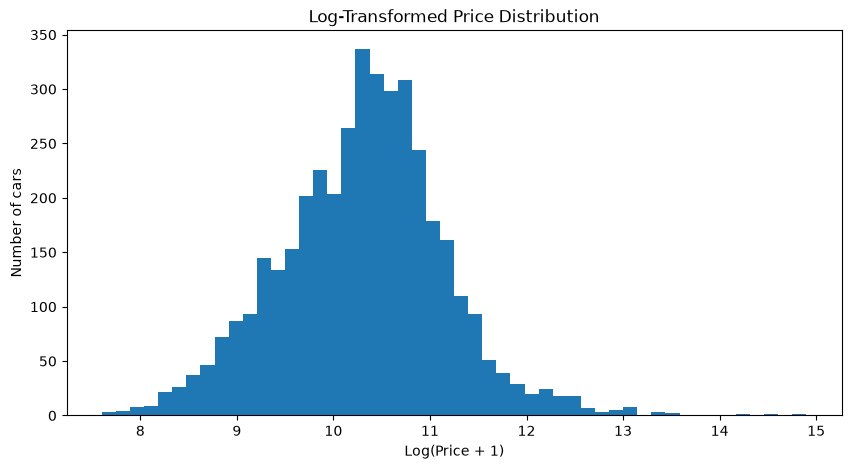

In [137]:
import numpy as np

plt.figure(figsize=(10, 5))
plt.hist(np.log1p(df["price"]), bins=50)
plt.xlabel("Log(Price + 1)")
plt.ylabel("Number of cars")
plt.title("Log-Transformed Price Distribution")
plt.show()

In [138]:

import json
from pathlib import Path

# Use the same folder that contains the original CSV.
# This does NOT reload or modify the raw dataset.
output_dir = data_path.parent

# Export the cleaned dataset for later ML training.
cleaned_path = output_dir / "used_cars_cleaned.csv"
df.to_csv(cleaned_path, index=False)

# Build dropdown options from the cleaned DataFrame.
car_options = {
    "brands": sorted(df["brand"].dropna().unique().tolist()),

    "models_by_brand": {
        brand: sorted(
            df.loc[df["brand"] == brand, "model"]
            .dropna()
            .unique()
            .tolist()
        )
        for brand in sorted(df["brand"].dropna().unique())
    },

    "fuel_types": sorted(df["fuel_type"].dropna().unique().tolist()),

    "transmission_types": sorted(
        df["transmission_type"].dropna().unique().tolist()
    ),

    "exterior_colors": sorted(df["ext_col"].dropna().unique().tolist()),

    "interior_colors": sorted(df["int_col"].dropna().unique().tolist()),

    "model_years": sorted(
        df["model_year"].dropna().astype(int).unique().tolist()
    ),

    "clean_titles": ["Yes", "Unknown"]
}

# Save the options as JSON for Django to use.
options_path = output_dir / "car_options.json"

with open(options_path, "w", encoding="utf-8") as file:
    json.dump(car_options, file, indent=2, ensure_ascii=False)

print("Cleaned dataset saved to:", cleaned_path)
print("Dropdown options saved to:", options_path)
print("Number of brands:", len(car_options["brands"]))
print("Number of brand-model combinations:", sum(
    len(models) for models in car_options["models_by_brand"].values()
))


Cleaned dataset saved to: c:\Users\manna\OneDrive\Desktop\usedcars\carvenv\raw\used_cars_cleaned.csv
Dropdown options saved to: c:\Users\manna\OneDrive\Desktop\usedcars\carvenv\raw\car_options.json
Number of brands: 57
Number of brand-model combinations: 1899
